# AI-Driven Phishing Threat Detection Prototype

**Unit 1 Mini Project - Introduction to AI and Cyber Security (ENSP355)**
Abhinav Kumar (2301730191) | B.Tech CSE (AIML)-C | K.R. Mangalam University

This notebook walks through the complete analysis on the UCI *Phishing Websites* dataset
(ID 327): threat-landscape EDA, three supervised classifiers (Logistic Regression, tuned
Decision Tree, Dense 64x32 MLP), and the operational threshold study. It complements the
pipeline in `main.py`; every figure below is produced by this notebook itself.

## 1. Setup

Reproducible configuration: fixed random seed, dataset path and the report's colour palette.

In [1]:
import platform
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score,
                             matthews_corrcoef, precision_score, recall_score,
                             roc_auc_score, roc_curve)
from sklearn.model_selection import (GridSearchCV, StratifiedKFold, cross_val_score,
                                     train_test_split)
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore")
%matplotlib inline

RANDOM_STATE = 42
BASE_DIR = Path.cwd().parent if Path.cwd().name == "src" else Path.cwd()
DATA_FILE = BASE_DIR / "data" / "phishing_websites.csv"

plt.rcParams.update({
    "figure.dpi": 110, "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold",
    "axes.grid": True, "grid.color": "#d9d9d9", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "legend.frameon": False,
})
C_PHISH, C_LEGIT = "#B23A48", "#2E6FA7"          # crimson / steel blue
MODEL_COLORS = {"Logistic Regression": "#4472C4", "Decision Tree": "#E67E22",
                "MLP (64x32)": "#27AE60"}

print(f"python {platform.python_version()} | numpy {np.__version__} | pandas {pd.__version__} "
      f"| scikit-learn {sklearn.__version__}")

python 3.14.0 | numpy 2.5.4 | pandas 3.1.1 | scikit-learn 1.9.1


## 2. Dataset and threat landscape

30 categorical indicators per website, coded **-1** (phishing signal), **0** (suspicious) and
**+1** (legitimate); the label is remapped to a binary `phishing = 1` target.

In [2]:
df = pd.read_csv(DATA_FILE)
df["phishing"] = (df["Result"] == -1).astype(int)
features = [c for c in df.columns if c not in ("Result", "phishing")]

print(f"samples: {len(df):,} | indicators: {len(features)} "
      f"| missing values: {df[features].isna().sum().sum()} "
      f"| duplicated feature profiles: {df.duplicated().sum():,}")
df.head()

samples: 11,055 | indicators: 30 | missing values: 0 | duplicated feature profiles: 5,206


,having_IP_Address,URL_Length,Shortining_Service,having_At_Symbol,double_slash_redirecting,Prefix_Suffix,having_Sub_Domain,SSLfinal_State,Domain_registeration_length,Favicon,...,Iframe,age_of_domain,DNSRecord,web_traffic,Page_Rank,Google_Index,Links_pointing_to_page,Statistical_report,Result,phishing
0,-1,1,1,1,-1,-1,-1,-1,-1,1,...,1,-1,-1,-1,-1,1,1,-1,-1,1
1,1,1,1,1,1,-1,0,1,-1,1,...,1,-1,-1,0,-1,1,1,1,-1,1
2,1,0,1,1,1,-1,-1,-1,-1,1,...,1,1,-1,1,-1,1,0,-1,-1,1
3,1,0,1,1,1,-1,-1,-1,1,1,...,1,-1,-1,1,-1,1,-1,1,-1,1
4,1,0,-1,1,1,-1,1,1,-1,1,...,1,-1,-1,0,-1,1,1,1,1,0


### 2.1 Class balance

4,898 phishing (44.3%) vs 6,157 legitimate (55.7%) - a mild imbalance, so no oversampling is
needed and accuracy remains a meaningful headline metric.

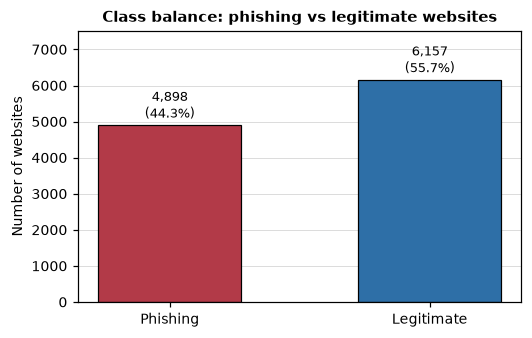

In [3]:
counts = df["phishing"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(5.2, 3.2))
bars = ax.bar(["Phishing", "Legitimate"], [counts[1], counts[0]], width=0.55,
              color=[C_PHISH, C_LEGIT], edgecolor="black", linewidth=0.8)
for bar, pct in zip(bars, ["44.3%", "55.7%"]):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 90,
            f"{int(bar.get_height()):,}\n({pct})", ha="center", va="bottom", fontsize=8.5)
ax.set_ylabel("Number of websites")
ax.set_ylim(0, counts.max() * 1.22)
ax.grid(axis="x", visible=False)
ax.set_title("Class balance: phishing vs legitimate websites")
plt.show()

### 2.2 Correlation structure

The class label correlates strongly with a compact indicator set led by `SSLfinal_State` and
`URL_of_Anchor`; `Favicon`/`port` and the client-side cluster
(`on_mouseover`/`RightClick`/`popUpWidnow`/`Iframe`) are near-redundant.

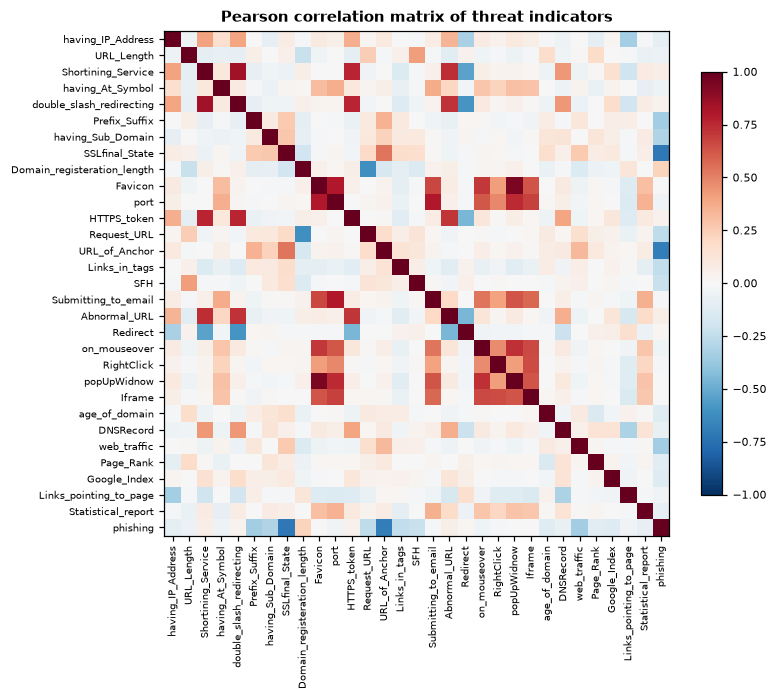

In [4]:
corr = df[features + ["phishing"]].corr()
fig, ax = plt.subplots(figsize=(7.4, 6.4))
im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=90, fontsize=6.5)
ax.set_yticks(range(len(corr)), corr.columns, fontsize=6.5)
ax.grid(visible=False)
ax.set_title("Pearson correlation matrix of threat indicators")
cbar = fig.colorbar(im, ax=ax, shrink=0.78)
cbar.ax.tick_params(labelsize=7)
plt.show()

### 2.3 Top threat indicators

SSL certificate state and anchor behaviour dominate (|r| > 0.69). One data-quality note: the
distributed copy of `Domain_registeration_length` is coded opposite to its published
definition - the models absorb the flipped coding, but it is worth auditing before reuse.

In [5]:
corr_target = (df[features].corrwith(df["phishing"])
               .sort_values(key=np.abs, ascending=False).head(10)
               .rename("pearson_r").reset_index().rename(columns={"index": "indicator"}))
corr_target["direction"] = np.where(corr_target["pearson_r"] < 0,
                                    "phishing signal (-1)", "legitimate signal (+1)")
corr_target

,indicator,pearson_r,direction
0,SSLfinal_State,-0.714741,phishing signal (-1)
1,URL_of_Anchor,-0.692935,phishing signal (-1)
2,Prefix_Suffix,-0.348606,phishing signal (-1)
3,web_traffic,-0.346103,phishing signal (-1)
4,having_Sub_Domain,-0.298323,phishing signal (-1)
5,Request_URL,-0.253372,phishing signal (-1)
6,Links_in_tags,-0.248229,phishing signal (-1)
7,Domain_registeration_length,0.225789,legitimate signal (+1)
8,SFH,-0.221419,phishing signal (-1)
9,Google_Index,-0.128950,phishing signal (-1)


### 2.4 Indicator distributions by class

Phishing pages concentrate on the -1 (phishing-signal) value for the strongest indicators,
while legitimate pages concentrate on +1.

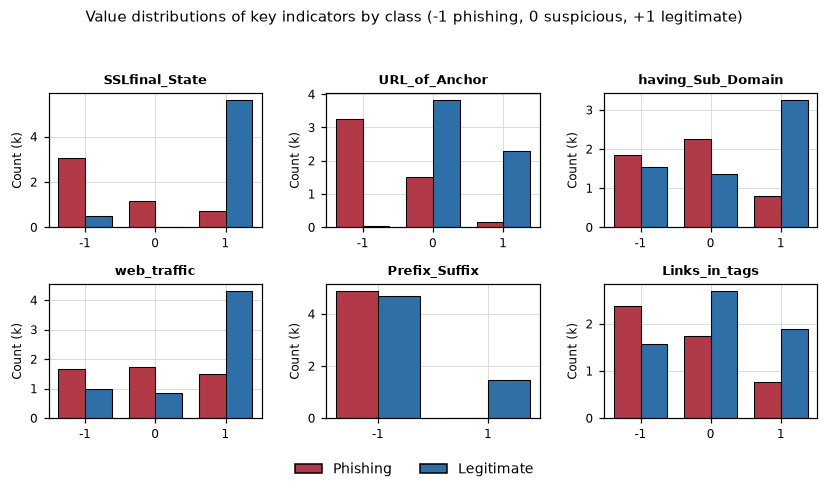

In [6]:
picks = ["SSLfinal_State", "URL_of_Anchor", "having_Sub_Domain",
         "web_traffic", "Prefix_Suffix", "Links_in_tags"]
fig, axes = plt.subplots(2, 3, figsize=(7.6, 4.4))
for ax, feat in zip(axes.flat, picks):
    ct = df.groupby([feat, "phishing"]).size().unstack(fill_value=0)
    ct = ct.reindex(sorted(ct.index))
    x = np.arange(len(ct.index))
    w = 0.38
    ax.bar(x - w / 2, ct[1] / 1000, width=w, color=C_PHISH, edgecolor="black", linewidth=0.7)
    ax.bar(x + w / 2, ct[0] / 1000, width=w, color=C_LEGIT, edgecolor="black", linewidth=0.7)
    ax.set_xticks(x, [str(v) for v in ct.index], fontsize=8)
    ax.set_title(feat, fontsize=8.5)
    ax.set_ylabel("Count (k)", fontsize=8)
    ax.tick_params(labelsize=8)
fig.legend([plt.Rectangle((0, 0), 1, 1, fc=C_PHISH, ec="black"),
            plt.Rectangle((0, 0), 1, 1, fc=C_LEGIT, ec="black")],
           ["Phishing", "Legitimate"], loc="lower center", ncol=2)
fig.suptitle("Value distributions of key indicators by class "
             "(-1 phishing, 0 suspicious, +1 legitimate)", fontsize=9.5)
fig.tight_layout(rect=(0, 0.06, 1, 0.94))
plt.show()

## 3. Supervised models (Tasks 3-4)

Stratified 80/20 split with a fixed seed; the test set is touched exactly once, at final
evaluation. The Decision Tree is tuned by 5-fold grid search and all three models are
cross-validated on the training partition.

In [7]:
X, y = df[features].values, df["phishing"].values
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
print(f"train: {len(X_train):,} | test: {len(X_test):,}")

models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    ]),
    "Decision Tree": Pipeline([
        ("model", DecisionTreeClassifier(random_state=RANDOM_STATE)),
    ]),
    "MLP (64x32)": Pipeline([
        ("scaler", StandardScaler()),
        ("model", MLPClassifier(hidden_layer_sizes=(64, 32), activation="relu", solver="adam",
                                early_stopping=True, validation_fraction=0.1,
                                max_iter=300, random_state=RANDOM_STATE)),
    ]),
}

grid = GridSearchCV(DecisionTreeClassifier(random_state=RANDOM_STATE),
                    param_grid={"max_depth": [4, 6, 8, 10, None],
                                "min_samples_leaf": [1, 2, 5, 10]},
                    scoring="f1", n_jobs=-1,
                    cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE))
grid.fit(X_train, y_train)
models["Decision Tree"].set_params(
    model__max_depth=grid.best_params_["max_depth"],
    model__min_samples_leaf=grid.best_params_["min_samples_leaf"])
print(f"best tree params: {grid.best_params_} (CV F1 = {grid.best_score_:.4f})")

cv = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
for name, model in models.items():
    acc = cross_val_score(model, X_train, y_train, cv=cv, scoring="accuracy")
    f1 = cross_val_score(model, X_train, y_train, cv=cv, scoring="f1")
    print(f"{name:<20} acc {acc.mean():.4f} +/- {acc.std():.4f} "
          f"| F1 {f1.mean():.4f} +/- {f1.std():.4f}")

train: 8,844 | test: 2,211


best tree params: {'max_depth': None, 'min_samples_leaf': 1} (CV F1 = 0.9503)


Logistic Regression  acc 0.9282 +/- 0.0043 | F1 0.9180 +/- 0.0049


Decision Tree        acc 0.9562 +/- 0.0038 | F1 0.9503 +/- 0.0041


MLP (64x32)          acc 0.9555 +/- 0.0042 | F1 0.9495 +/- 0.0046


### 3.1 Hold-out test benchmark

In [8]:
results, probs = {}, {}
for name, model in models.items():
    t0 = time.perf_counter()
    model.fit(X_train, y_train)
    train_s = time.perf_counter() - t0
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    probs[name] = y_prob
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    results[name] = {
        "accuracy": accuracy_score(y_test, y_pred),
        "precision": precision_score(y_test, y_pred),
        "recall": recall_score(y_test, y_pred),
        "f1": f1_score(y_test, y_pred),
        "roc_auc": roc_auc_score(y_test, y_prob),
        "mcc": matthews_corrcoef(y_test, y_pred),
        "train_s": round(train_s, 2),
        "FP": int(fp), "FN": int(fn),
    }

res_df = pd.DataFrame(results).T.round(4)
res_df

,accuracy,precision,recall,f1,roc_auc,mcc,train_s,FP,FN
Logistic Regression,0.9281,0.9344,0.9010,0.9174,0.9785,0.8542,0.06,62.0,97.0
Decision Tree,0.9697,0.9760,0.9551,0.9654,0.9764,0.9386,0.03,23.0,44.0
MLP (64x32),0.9656,0.9699,0.9520,0.9609,0.9944,0.9304,3.46,29.0,47.0


### 3.2 Error anatomy

False negatives expose users to phishing; false positives block legitimate sites - the two
error types are not interchangeable (quantified in Section 4).

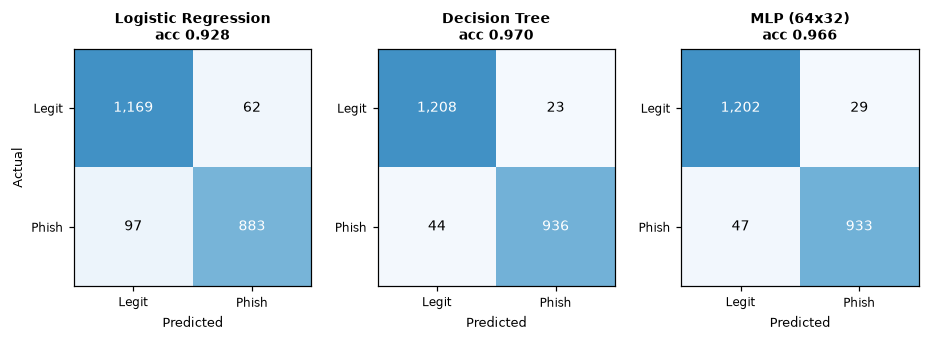

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(8.6, 2.9))
for ax, (name, res) in zip(axes, results.items()):
    cm = confusion_matrix(y_test, models[name].predict(X_test))
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=cm.max() * 1.6)
    for (i, j), val in np.ndenumerate(cm):
        ax.text(j, i, f"{val:,}", ha="center", va="center", fontsize=9,
                color="white" if val > cm.max() * 0.75 else "black")
    ax.set_xticks([0, 1], ["Legit", "Phish"], fontsize=8)
    ax.set_yticks([0, 1], ["Legit", "Phish"], fontsize=8)
    ax.set_xlabel("Predicted", fontsize=8.5)
    ax.grid(visible=False)
    ax.set_title(f"{name}\nacc {res['accuracy']:.3f}", fontsize=9)
axes[0].set_ylabel("Actual", fontsize=8.5)
fig.tight_layout()
plt.show()

### 3.3 Ranking quality

The MLP dominates the ROC surface across the operating range (AUC 0.9944) - the property that
matters when the decision threshold must move.

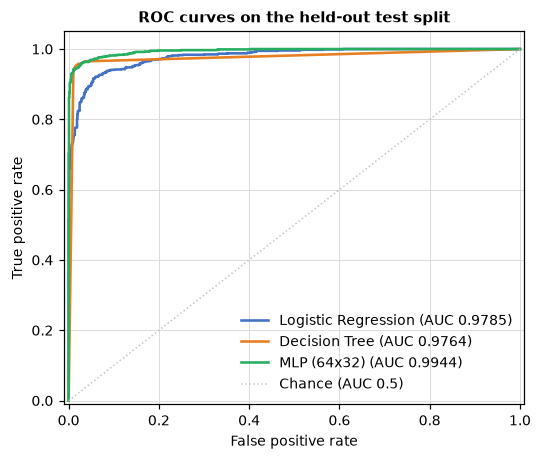

In [10]:
fig, ax = plt.subplots(figsize=(5.4, 4.4))
for name, y_prob in probs.items():
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    ax.plot(fpr, tpr, color=MODEL_COLORS[name], linewidth=1.7,
            label=f"{name} (AUC {results[name]['roc_auc']:.4f})")
ax.plot([0, 1], [0, 1], color="#c4c4c4", linewidth=1.0, linestyle=":", label="Chance (AUC 0.5)")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_xlim(-0.01, 1.01)
ax.set_ylim(-0.01, 1.05)
ax.set_title("ROC curves on the held-out test split")
ax.legend(loc="lower right")
plt.show()

### 3.4 Metrics and training cost

The tuned Decision Tree is the strongest single-threshold classifier; the MLP offers the best
ranking quality. All models train in seconds and classify in microseconds.

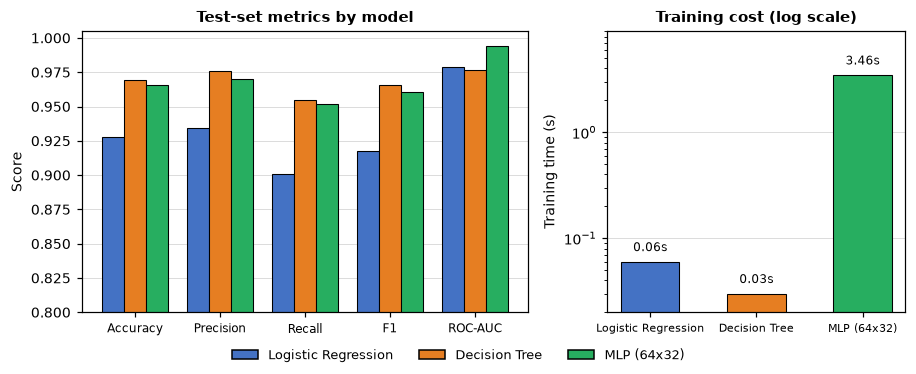

In [11]:
metrics = ["accuracy", "precision", "recall", "f1", "roc_auc"]
labels = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]
names = list(results.keys())
x = np.arange(len(metrics))
w = 0.26

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8.4, 3.4), gridspec_kw={"width_ratios": [3, 2]})
for name in names:
    ax1.bar(x + (names.index(name) - 1) * w, [results[name][m] for m in metrics],
            width=w, color=MODEL_COLORS[name], edgecolor="black", linewidth=0.7)
ax1.set_xticks(x, labels, fontsize=8)
ax1.set_ylim(0.80, 1.005)
ax1.set_ylabel("Score")
ax1.grid(axis="x", visible=False)
ax1.set_title("Test-set metrics by model")

train_s = [results[n]["train_s"] for n in names]
bars = ax2.bar(names, train_s, width=0.55, color=[MODEL_COLORS[n] for n in names],
               edgecolor="black", linewidth=0.7)
for bar, v in zip(bars, train_s):
    ax2.text(bar.get_x() + bar.get_width() / 2, bar.get_height() * 1.18, f"{v:.2f}s",
             ha="center", va="bottom", fontsize=8)
ax2.set_yscale("log")
ax2.set_ylim(0.02, 9)
ax2.set_ylabel("Training time (s)")
ax2.grid(axis="x", visible=False)
ax2.tick_params(axis="x", labelsize=7.5)
ax2.set_title("Training cost (log scale)")

handles = [plt.Rectangle((0, 0), 1, 1, fc=MODEL_COLORS[n], ec="black") for n in names]
fig.legend(handles, names, loc="lower center", ncol=3, fontsize=8.5)
fig.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()

## 4. Operational threshold analysis (Task 5)

Sweeping the MLP decision threshold: a low threshold maximises protection (high recall), a
high threshold minimises user disruption. A linear cost model
(`cost = FN x c_FN + FP x c_FP`) makes the asymmetry explicit - the threshold is a governance
decision, not a technical default.

FN:FP cost 1:1 -> optimal threshold 0.65 (FP 15, FN 57)
FN:FP cost 10:1 -> optimal threshold 0.05 (FP 177, FN 10)
FN:FP cost 20:1 -> optimal threshold 0.05 (FP 177, FN 10)


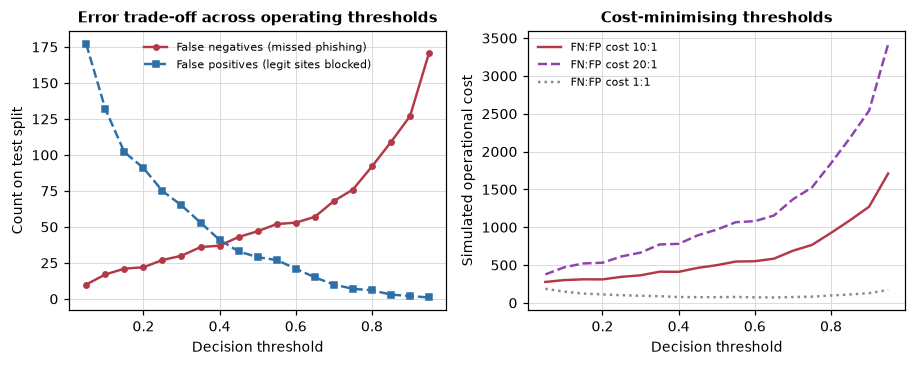

,threshold,precision,recall,accuracy,FP,FN
0,0.05,0.846,0.990,0.915,177,10
1,0.10,0.879,0.983,0.933,132,17
2,0.15,0.904,0.979,0.944,102,21
3,0.20,0.913,0.978,0.949,91,22
4,0.25,0.927,0.972,0.954,75,27
5,0.30,0.936,0.969,0.957,65,30
6,0.35,0.947,0.963,0.960,53,36
7,0.40,0.958,0.962,0.965,41,37
8,0.45,0.966,0.956,0.966,33,43
9,0.50,0.970,0.952,0.966,29,47


In [12]:
rows = []
for t in np.arange(0.05, 0.96, 0.05):
    y_pred = (probs["MLP (64x32)"] >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    rows.append({"threshold": round(t, 2),
                 "precision": precision_score(y_test, y_pred, zero_division=0),
                 "recall": recall_score(y_test, y_pred),
                 "accuracy": accuracy_score(y_test, y_pred),
                 "FP": int(fp), "FN": int(fn)})
thr_df = pd.DataFrame(rows)

for ratio in (1, 10, 20):
    costs = thr_df["FN"] * ratio + thr_df["FP"]
    i = costs.idxmin()
    print(f"FN:FP cost {ratio}:1 -> optimal threshold {thr_df.loc[i, 'threshold']:.2f} "
          f"(FP {thr_df.loc[i, 'FP']}, FN {thr_df.loc[i, 'FN']})")

t = thr_df["threshold"]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8.4, 3.4))
ax1.plot(t, thr_df["FN"], marker="o", color=C_PHISH, linewidth=1.6, markersize=3.5,
         label="False negatives (missed phishing)")
ax1.plot(t, thr_df["FP"], marker="s", color=C_LEGIT, linewidth=1.6, markersize=3.5,
         linestyle="--", label="False positives (legit sites blocked)")
ax1.set_xlabel("Decision threshold")
ax1.set_ylabel("Count on test split")
ax1.set_title("Error trade-off across operating thresholds")
ax1.legend(fontsize=7.5)

for ratio, ls, cc in zip((10, 20, 1), ("-", "--", ":"), ("#B23A48", "#8E44AD", "#7F8C8D")):
    ax2.plot(t, thr_df["FN"] * ratio + thr_df["FP"], linestyle=ls, color=cc, linewidth=1.6,
             label=f"FN:FP cost {ratio}:1")
ax2.set_xlabel("Decision threshold")
ax2.set_ylabel("Simulated operational cost")
ax2.set_title("Cost-minimising thresholds")
ax2.legend(fontsize=7.5)
fig.tight_layout()
plt.show()

thr_df.round(3)

## 5. Key findings

- **Threat signal**: SSL certificate state (`SSLfinal_State`, r = -0.71) and anchor behaviour
  (`URL_of_Anchor`, r = -0.69) dominate; together they make the classes nearly linearly
  separable.
- **Best single-threshold model**: the tuned Decision Tree (accuracy 96.97%, F1 0.9654,
  0.04 s training, sub-microsecond inference).
- **Best ranking model**: the MLP 64x32 (accuracy 96.56%, ROC-AUC 0.9944) - the widest usable
  envelope for threshold tuning.
- **Operating points**: balanced costs optimise near threshold 0.65 (15 FP / 57 FN); when a
  compromise costs 10x a false alert, a protective low threshold maximises recall.
- **Recommended posture**: autonomous blocking only above ~0.80-0.90 (precision > 99%),
  analyst review for 0.40-0.80, and scheduled retraining on analyst verdicts.